---
authors:
  - name: Emma Pidduck
    url: https://www.linkedin.com/in/emmapidduck/
---

# Day 27 · New tool — The whole archive, one line

### #30DayMapChallenge 2026 · ARCO-ERA5 (cloud-native Zarr) · Map by Emma Pidduck

The new tool here isn't a library — it's a **way of holding data**. The entire **ERA5 reanalysis**
— 1940 to now, hundreds of variables, hourly, global, *petabytes* — sits in a public cloud bucket
as **analysis-ready Zarr**. You don't download it. You open it like one array and reach in for the
exact slice you want, whether it's a storm from last year or one from 1940.

To prove it, this map pulls a single hour of a **recent** storm: **Storm Ciarán**, the explosive
"bomb cyclone" that crossed the western English Channel overnight on **1–2 November 2023** —
hurricane-force winds across Brittany, the Channel Islands and southern England. The *same* one
line would fetch the 1987 Great Storm on [Day 6](day06_vintage); the archive doesn't care how far
back you reach.

## Method

- Open **ARCO-ERA5** (Analysis-Ready, Cloud-Optimised ERA5, published by Google on GCS) with
  `xarray.open_zarr` — no credentials, no download, just a URL. This is the **full hourly** cube
  (`full_37-1h-0p25deg`), which runs right up to the present.
- **Random-access** one timestamp, `2023-11-02 04 UTC`, and a window over the British Isles and
  the Channel — the 10 m wind components and mean-sea-level pressure. One `.sel(...).compute()`
  pulls only the handful of chunks that intersect the request: a few megabytes out of a petabyte.
- Combine the wind components into speed; shade it; overlay MSLP isobars every 4 hPa; mark the centre.

**Why this is the "new tool":** every other day in this series downloads a GRIB file first. Here
there is no file. The cube is remote, chunked, and lazily read — the model only touches the bytes
it needs. That is what makes a petabyte archive usable from a laptop.

## Licence & attribution

**ERA5** is produced by **ECMWF** for the **Copernicus Climate Change Service (C3S)**.
**ARCO-ERA5** is a cloud-optimised mirror hosted by **Google** (`gs://gcp-public-data-arco-era5`),
publicly readable.

> Contains modified Copernicus Climate Change Service information. Generated using Copernicus
> Climate Change Service information; neither the European Commission nor ECMWF is responsible
> for any use of the Copernicus information.

ARCO-ERA5: Carver & Merose (2023). ERA5: Hersbach et al. (2020), *QJRMS*.

## Tools

| Tool | Role |
|---|---|
| [`xarray`](https://xarray.dev) + [`zarr`](https://zarr.readthedocs.io) | open the remote cube, lazily |
| [`gcsfs`](https://gcsfs.readthedocs.io) | read Google Cloud Storage anonymously |
| `cartopy` · `matplotlib` | projection, isobars, the storm render |

New dependencies versus the forecast days: **`zarr`** and **`gcsfs`**. No account, no key —
the bucket is public (`token="anon"`).

In [1]:
# Run once if needed (uncomment):
#!pip install zarr gcsfs xarray cartopy matplotlib

import time, warnings
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap, to_rgba
import cartopy.crs as ccrs
import cartopy.feature as cfeature
warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]
BG, INK, MUT = "#ffffff", "#1d2230", "#6b7280" 

### Configuration

Change `WHEN` to reach for any other hour in the record — the 1987 Great Storm, the 2003 heatwave,
last week. The read cost barely moves: you only ever pull the chunks you touch. This is the **full
hourly** ARCO-ERA5 cube, so unlike the 1959–2022 6-hourly mirror it runs to the present day.

In [2]:
URL  = "gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3"
WHEN = "2023-11-02T04:00"      # Storm Ciaran, near its deepest over the western Channel
WIN  = dict(longitude=slice(-18, 14), latitude=slice(62, 42))

## Open the cloud cube and reach in

The whole archive is one `open_zarr`. The `.sel(...).compute()` is where bytes actually move —
and only for the slice requested. We pull the 10 m wind components and MSLP, then form the speed.

In [3]:
t0 = time.time()
ds = xr.open_zarr(URL, storage_options={"token": "anon"}, chunks=None)   # chunks=None: skip the dask graph, read the slice directly
# longitudes are 0..360; roll to -180..180 so a UK/France window doesn't straddle the seam
ds = ds.assign_coords(longitude=(((ds.longitude + 180) % 360) - 180)).sortby("longitude")
sub = ds[["10m_u_component_of_wind", "10m_v_component_of_wind", "mean_sea_level_pressure"]].sel(
    time=WHEN, **WIN).compute()
dt = time.time() - t0

ws   = np.hypot(sub["10m_u_component_of_wind"], sub["10m_v_component_of_wind"])
mslp = sub["mean_sea_level_pressure"] / 100.0
lon, lat = ws.longitude.values, ws.latitude.values
print(f"opened the archive and pulled one hour in {dt:.1f} s")
print(f"window {dict(ws.sizes)}   wind to {float(ws.max()):.1f} m/s   lowest MSLP {float(mslp.min()):.1f} hPa")

opened the archive and pulled one hour in 8.2 s
window {'latitude': 81, 'longitude': 129}   wind to 29.3 m/s   lowest MSLP 953.7 hPa


In [4]:
# locate the storm centre (grid minimum of MSLP)
j = np.unravel_index(int(mslp.values.argmin()), mslp.shape)
lo_lat, lo_lon, lo_p = float(lat[j[0]]), float(lon[j[1]]), float(mslp.values[j])
print(f"low centre: {lo_p:.0f} hPa at {lo_lat:.1f}N {abs(lo_lon):.1f}{'W' if lo_lon<0 else 'E'}")

low centre: 954 hPa at 50.2N 3.0W


### Colour — calm → storm, colourblind-safe

Pale (calm) to deep indigo (fierce). **Monotonic in luminance** (verified), so wind speed reads
by brightness alone for every colour-vision type — and it keeps the house white background.

In [5]:
CMAP = LinearSegmentedColormap.from_list("storm", [
    "#fbfcfe", "#dcebf3", "#9fd0db", "#56b0c6", "#2f7fb8", "#3a4fa0", "#3b2f7a", "#241a4d"])
rgb = np.array([to_rgba(CMAP(t))[:3] for t in np.linspace(0, 1, 256)])
lum = 0.2126*rgb[:,0] + 0.7152*rgb[:,1] + 0.0722*rgb[:,2]
mono = (np.diff(lum) <= 1e-3).all() or (np.diff(lum) >= -1e-3).all()
print("storm ramp luminance-monotonic:", bool(mono), f"({lum[0]:.2f} -> {lum[-1]:.2f})")

storm ramp luminance-monotonic: True (0.99 -> 0.12)


## Render

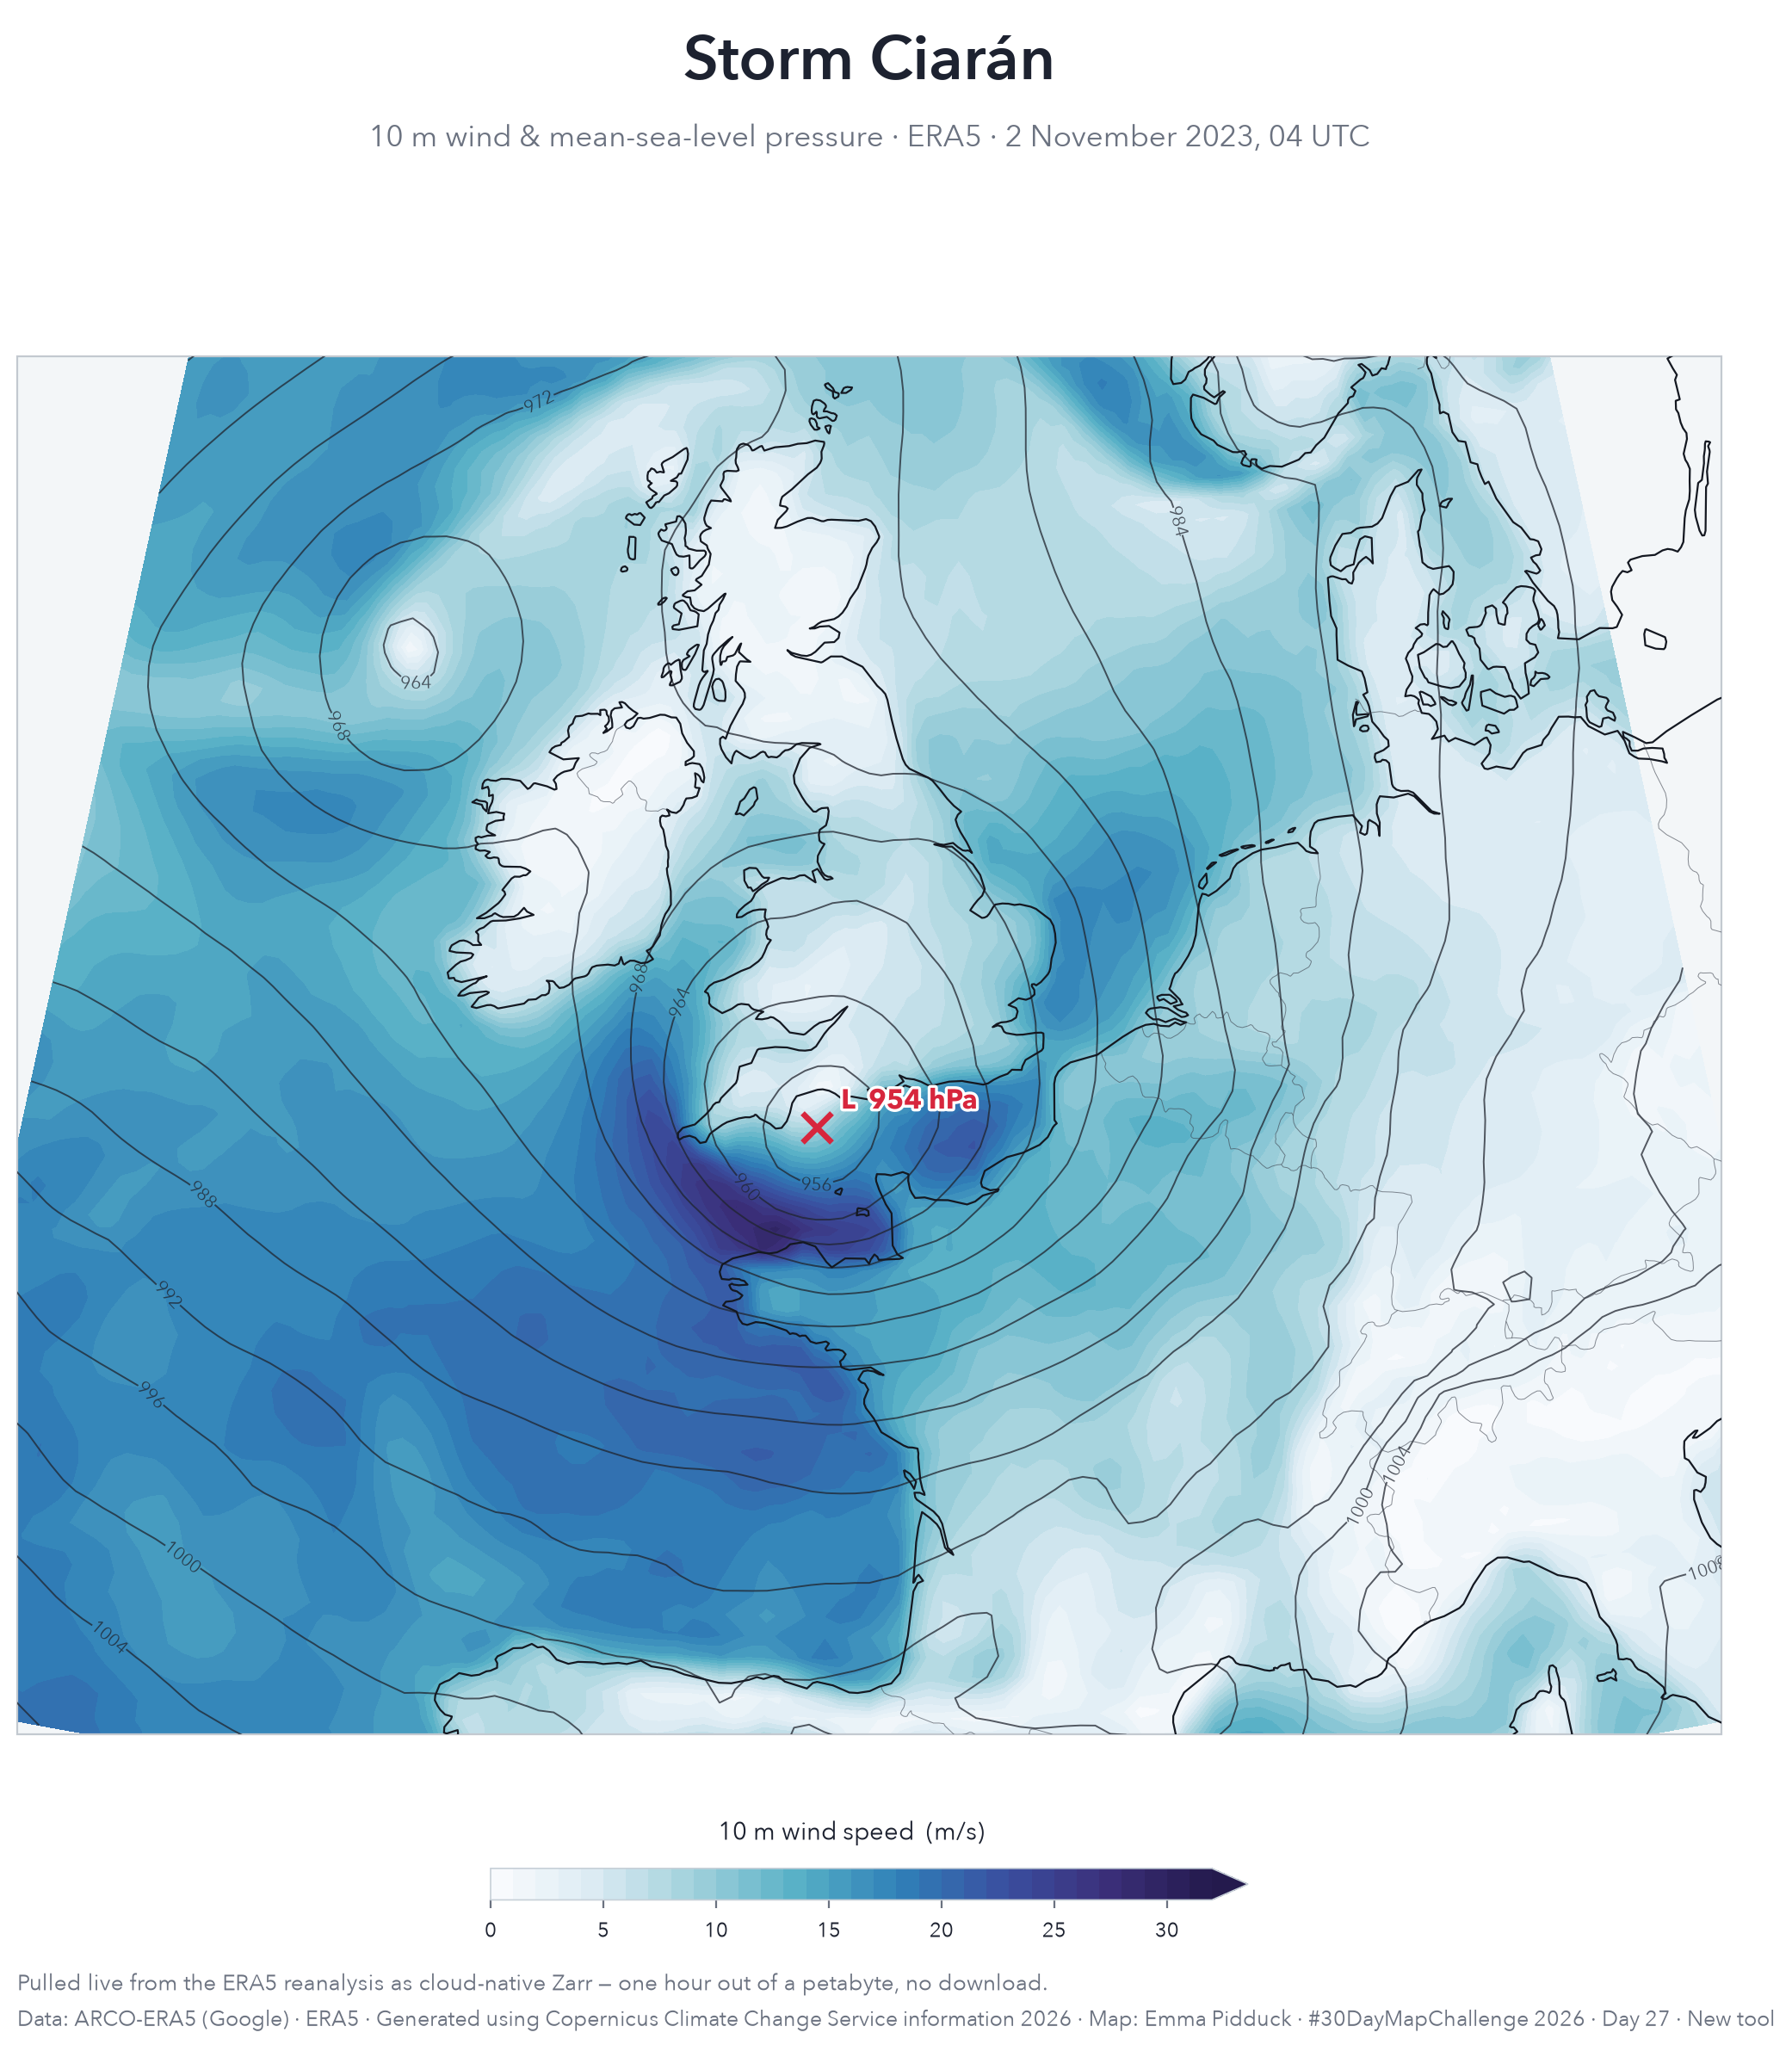

In [6]:
proj = ccrs.LambertConformal(central_longitude=-2, central_latitude=50, standard_parallels=(44, 56))
tp = dict(transform=ccrs.PlateCarree())
fig = plt.figure(figsize=(11, 12.2), dpi=200); fig.patch.set_facecolor(BG)
ax = fig.add_axes([0.05, 0.095, 0.90, 0.80], projection=proj)
ax.set_extent([-16, 12, 42, 59], crs=ccrs.PlateCarree()); ax.set_facecolor("#f3f6f8")

cf = ax.contourf(lon, lat, ws.values, levels=np.arange(0, 32.1, 1.0), cmap=CMAP, extend="max", zorder=0, **tp)
cs = ax.contour(lon, lat, mslp.values, levels=np.arange(936, 1041, 4),
                colors="#20242e", linewidths=0.7, alpha=0.75, zorder=3, **tp)
ax.clabel(cs, fmt="%d", fontsize=7.5, inline=True, inline_spacing=2)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor="#141821", linewidth=0.8, zorder=4)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="#3a3f4a", linewidth=0.35, alpha=0.6, zorder=4)
ax.spines["geo"].set_edgecolor("#c3c9d0"); ax.spines["geo"].set_linewidth(0.8)

halo = [pe.withStroke(linewidth=2.4, foreground="white")]
ax.plot(lo_lon, lo_lat, marker="x", ms=12, mew=2.4, color="#d7263d", transform=ccrs.PlateCarree(), zorder=6)
ax.annotate(f"L  {lo_p:.0f} hPa", (lo_lon, lo_lat), xytext=(10, 8), textcoords="offset points",
            transform=ccrs.PlateCarree(), fontsize=11.5, fontweight="bold", color="#d7263d",
            zorder=6, path_effects=halo)

cax = fig.add_axes([0.30, 0.088, 0.40, 0.015])
cb = fig.colorbar(cf, cax=cax, orientation="horizontal", extend="max", ticks=[0,5,10,15,20,25,30])
cb.set_label("10 m wind speed  (m/s)", color=INK, fontsize=10.5, labelpad=12)
cb.ax.xaxis.set_label_position("top")
cb.ax.xaxis.set_tick_params(color=MUT, labelsize=8.5); plt.setp(plt.getp(cb.ax,"xticklabels"), color=INK)
cb.outline.set_edgecolor("#c7d0d8"); cb.outline.set_linewidth(0.6)

fig.text(0.5, 0.955, "Storm Ciar\u00e1n", ha="center", color=INK, fontsize=26, fontfamily=["Avenir Next Demi Bold", "Arial", "DejaVu Sans"])
fig.text(0.5, 0.923, "10 m wind & mean-sea-level pressure \u00b7 ERA5 \u00b7 2 November 2023, 04 UTC",
         ha="center", color=MUT, fontsize=12.5)
fig.text(0.05, 0.045, "Pulled live from the ERA5 reanalysis as cloud-native Zarr \u2014 one hour out of a petabyte, no download.",
         color=MUT, fontsize=9.3)
fig.text(0.05, 0.028, "Data: ARCO-ERA5 (Google) \u00b7 ERA5 \u00b7 Generated using Copernicus Climate Change Service information 2026 \u00b7 Map: Emma Pidduck \u00b7 #30DayMapChallenge 2026 \u00b7 Day 27 \u00b7 New tool",
         color=MUT, fontsize=9)
fig.savefig("day27_new_tool_zarr.png", facecolor=BG, bbox_inches="tight")
plt.show()

## Note

ERA5 at 0.25° brings the low to about **954 hPa** — right next to the **953.3 hPa** measured at
Plymouth that night, England's lowest November pressure on record. The tell-tale signature of a
damaging windstorm is here: the strongest 10 m winds are **not** at the centre but on its
**southern flank** — the dark band sweeping Brittany, the Channel Islands and southern England,
which is exactly where the destruction fell. Gusts reached **207 km/h (129 mph)** at Pointe du Raz
in Brittany; around 1.2 million homes lost power in France, and at least 14 people died across
western Europe.

The point of the day is the plumbing. A petabyte archive spanning 1940 to now, and the map above
cost one `open_zarr` and one `.sel`. **Zarr + object storage** is how climate data is increasingly
served — ARCO-ERA5, the Copernicus EWC, Pangeo, dynamical.org — and it changes what you can do
from a laptop.

*A fourth way to get ECMWF data, after the IFS open-data GRIBs, MeteoSwiss ICON-CH1, and the
Copernicus CDS. Day 2 Lines · Day 6 Vintage (the 1987 storm) · Day 20 Hexagons · Day 22
Projections · Day 26 Water · Day 28 Feeling.*
